<a href="https://colab.research.google.com/github/gheriya-rahima/portofolio/blob/kaggle/flight_price_analysis_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prediksi Harga Tiket Pesawat (Domestik India : 6 kota metropolitan) | Berdasarkan web 'Easemytrip' [11.2.2022 - 31.3.2022]
### dataset telah di cleaning

Tujuan bisnis: fitur "harga terbaik" dan "beli sekarang vs tunggu" untuk Online Travel Agent (OTA).

5 pertanyaan :

1. Apakah harga bervariasi menurut maskapai?
2. Bagaimana harga terpengaruh jika tiket dibeli hanya 1 atau 2 hari sebelum keberangkatan?
3. Apakah harga tiket berubah berdasarkan waktu keberangkatan dan waktu kedatangan?
4. Bagaimana harga berubah menurut kota asal dan kota tujuan?
5. Bagaimana harga tiket berbeda antara kelas Economy dan Business?

In [3]:
# -q digunakan agar outputnya singkat
%pip install -q shap statsmodels lightgbm

In [6]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
import lightgbm as lgb, shap

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# panggil data
DATA = "Clean_Dataset.csv"
IN_COLAB = "google.colab" in str(get_ipython())
if IN_COLAB and not os.path.exists(DATA):
    # file unggah manual
    from google.colab import files
    uploaded = files.upload()
    DATA = list(uploaded.keys())[0]

df = pd.read_csv(DATA)
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")]) # menghapus kolom tanpa makna (berisi penomeran saja)
print(df.shape); df.head()

Saving Clean_Dataset.csv to Clean_Dataset.csv
(300153, 11)


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


## 1. Cek struktur data, data missing, dan statistika deskriptif

In [7]:
print(df.dtypes.to_string(), "\n") # tipe data masing" kolom
print("Missing values:", int(df.isna().sum().sum())) # menunjukkan jumlah tabel dengan data kosong
print("Baris duplikat penuh:", int(df.duplicated().sum())) # jumlah data perbaris yang duplikat
print("Jumlah baris (banyak data):", df.shape[0])
key = ["airline","flight","source_city","destination_city","class"] # dengan kombinasi 4 kategori tersebut, terdapat berapa kombinasi --> menunjukkan kode penerbangan
print("jumlah kode penerbangan:", df.groupby(key).ngroups)
print("jumlah (berdasarkan harian) dari berbagai kode penerbangan:", int(df.duplicated(key+["days_left"]).sum())) # berdasarkan kode penerbangan, namun sudah dikelompokkan berdssarkan harinya (biar kehitung ada berapa penerbangannya)
df.describe().round(2)

airline              object
flight               object
source_city          object
departure_time       object
stops                object
arrival_time         object
destination_city     object
class                object
duration            float64
days_left             int64
price                 int64 

Missing values: 0
Baris duplikat penuh: 0
Jumlah baris (banyak data): 300153
jumlah kode penerbangan: 5052
jumlah (berdasarkan harian) dari berbagai kode penerbangan: 145095


,duration,days_left,price
count,300153.00,300153.00,300153.00
mean,12.22,26.00,20889.66
std,7.19,13.56,22697.77
min,0.83,1.00,1105.00
25%,6.83,15.00,4783.00
50%,11.25,26.00,7425.00
75%,16.17,38.00,42521.00
max,49.83,49.00,123071.00


**Temuan penting dari cek data:**
- Data bersih (tidak ada missing value atau duplikat penuh), harga dalam **rupee India (INR)**.
- Kode penerbangan yang sama muncul berkali-kali pada `days_left` (hari pengamatan menuju hari keberangkatan) yang sama, artinya satu kode penerbangan mewakili banyak tanggal. Konsekuensinya: **observasi tidak independen** terklaster berdasarkan setiap kode penerbangan, bukan independen tiket masing masing.
- Data adalah **cross-section**, terdapat banyak tawaran tiket, bukan pelacakan harga satu tiket yang sama dari waktu ke waktu.

## 2. Distribusi harga


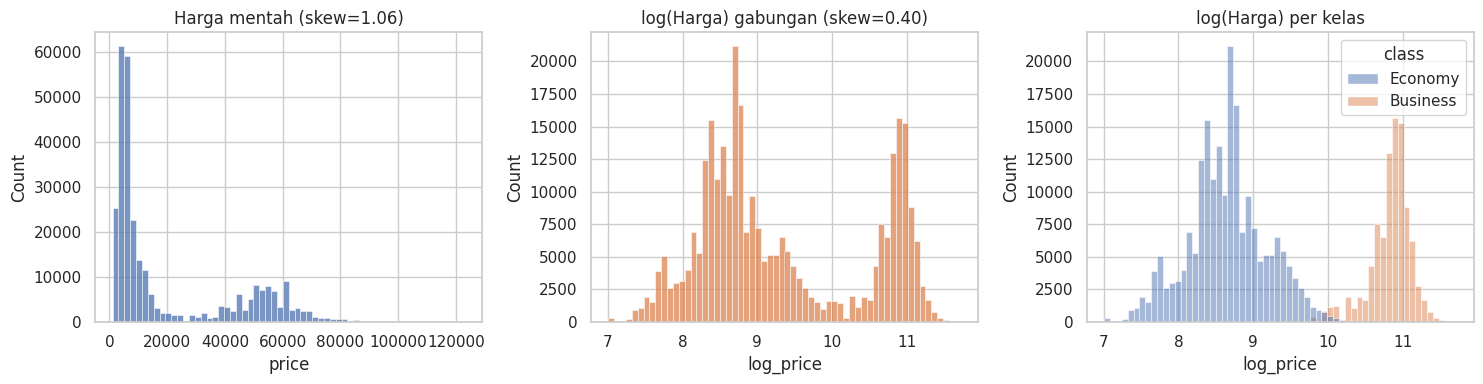

           count     mean   median      std    min     max
class                                                     
Business   93487  52540.0  53164.0  12969.0  12000  123071
Economy   206666   6572.0   5772.0   3744.0   1105   42349
Business skew raw=-0.10 | skew log=-1.21
Economy skew raw=1.70 | skew log=0.04


In [8]:
df["log_price"] = np.log(df["price"])
fig, ax = plt.subplots(1, 3, figsize=(15,4))
sns.histplot(df.price, bins=60, ax=ax[0]); ax[0].set_title(f"Harga mentah (skew={df.price.skew():.2f})") # ukuran kemiringan distribusi
sns.histplot(df.log_price, bins=60, ax=ax[1], color="C1"); ax[1].set_title(f"log(Harga) gabungan (skew={df.log_price.skew():.2f})")
sns.histplot(data=df, x="log_price", hue="class", bins=60, ax=ax[2]); ax[2].set_title("log(Harga) per kelas")
plt.tight_layout(); plt.show()
print(df.groupby("class").price.agg(["count","mean","median","std","min","max"]).round(0))
for c,g in df.groupby("class"): print(c, "skew raw=%.2f | skew log=%.2f" % (g.price.skew(), np.log(g.price).skew()))

berdasarkan harganya, distribusi data menunjukkan harga pesawat berdistribusi tidak nomral, data skew right (data miring kekanan). sehingga agar berdistribusi normal, data yang bersifat multiplikatif, dilakukan transformasi log.

## 3. EDA (exploratory data analys) dan Simpson's paradox

SIMPSON'S PARADOX : fenomena hubungan pada suatu kelompok data tertentu BERBEDA (berybah/berbalik) dengan hasil, semua kelompok ketika digabungkan.

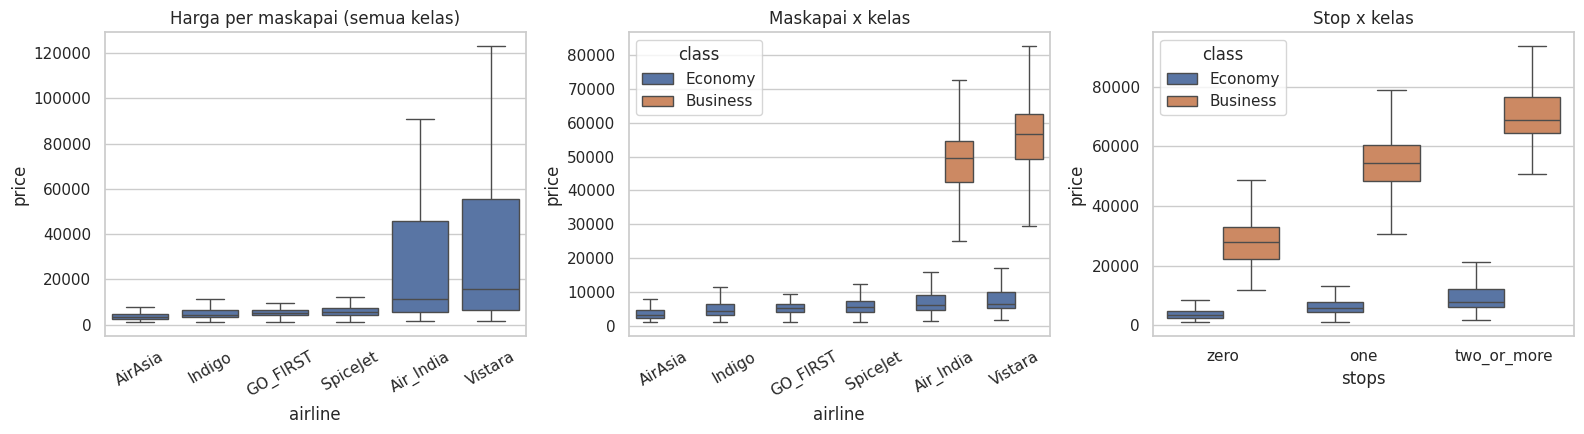

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16,4.5))
order = df.groupby("airline").price.median().sort_values().index # order = sortvalues, agar mengurutkan median dari yang termurah
sns.boxplot(data=df, x="airline", y="price", order=order, ax=ax[0], showfliers=False); ax[0].set_title("Harga per maskapai (semua kelas)"); ax[0].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="airline", y="price", hue="class", order=order, ax=ax[1], showfliers=False); ax[1].set_title("Maskapai x kelas"); ax[1].tick_params(axis="x", rotation=30) # 'showfliers=false' menyembynyikan titik outlier
sns.boxplot(data=df, x="stops", y="price", hue="class", order=["zero","one","two_or_more"], ax=ax[2], showfliers=False); ax[2].set_title("Stop x kelas")
plt.tight_layout(); plt.show()

In [10]:
raw = df.groupby("stops").price.mean().round(0).rename("Mean mentah (semua kelas)") # dengan pengkategorian berdasarkan 'stop'
byc = df.groupby(["stops","class"]).price.mean().unstack().round(0)
display(pd.concat([raw, byc], axis=1).loc[["zero","one","two_or_more"]])
print("Distribusi kelas per kategori stop (%):")
display((pd.crosstab(df.stops, df["class"], normalize="index")*100).round(1).loc[["zero","one","two_or_more"]])
print("Maskapai yang menjual Business:", sorted(df[df['class']=='Business'].airline.unique()))

,Mean mentah (semua kelas),Business,Economy
stops,,,
zero,9376.0,27846.0,4013.0
one,22901.0,54687.0,6813.0
two_or_more,14113.0,70128.0,9142.0


Distribusi kelas per kategori stop (%):


class,Business,Economy
stops,,
zero,22.5,77.5
one,33.6,66.4
two_or_more,8.2,91.8


Maskapai yang menjual Business: ['Air_India', 'Vistara']


Berdasarkan data maskapai, berdasarkan stop, KHUSUS untuk maskapai dengan class kategori business, pada kelas ekonomi ditemukan harga ekonomi one stop INR 66.4 ribu yang menunjukkan **lebih murah** jika dibandingkan dengan stop one_or_more yaitu INR 91.8 ribu.

Namun. ketika data maskapai secara keseluruhan, dengan fokus berdasarkan 'stop' nya. ketika **secara keseluruhan** (semua kelas) memiliki harga one stop INR 22.9 ribu **lebih mahal** dibandingkan harga two_or_more stop dengan harga INR 14.1 ribu



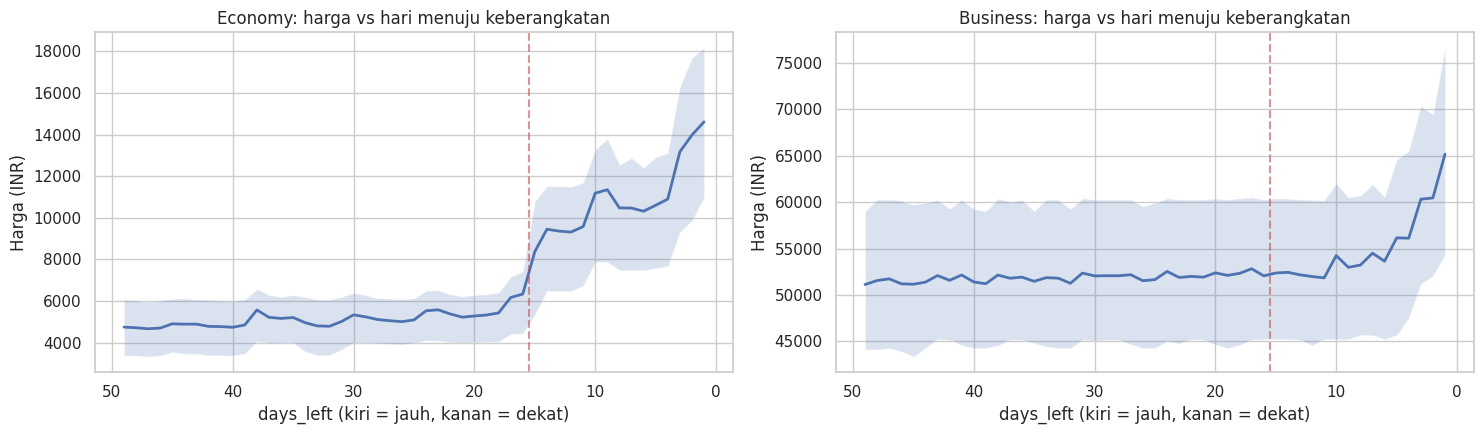

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15,4.5))
for c, a in zip(["Economy","Business"], ax):
    d = df[df["class"]==c]
    s = d.groupby("days_left").price.agg(["mean", lambda x: x.quantile(.25), lambda x: x.quantile(.75)]) # garis rata" menunjukkan tren
    s.columns = ["mean","q25","q75"]
    a.plot(s.index, s["mean"], lw=2); a.fill_between(s.index, s.q25, s.q75, alpha=.2) # fill between untuk menampilkan sebaran
    a.axvline(15.5, ls="--", c="r", alpha=.6); a.invert_xaxis() # axvline untuk menandai ambang di sekitar hari ke-15,invert_xaxis membalik sumbu x, sehingga waktu bergerak dari jauh ke dekat (hari h)
    a.set_title(f"{c}: harga vs hari menuju keberangkatan"); a.set_xlabel("days_left (kiri = jauh, kanan = dekat)"); a.set_ylabel("Harga (INR)")
plt.tight_layout(); plt.show()

pada kategori ekonomi maupun bisnis, menunjukkan harga **meningkat tajam**, sejak 15 hari sebelum keberangkatan hingga semakin dekat menuju hari keberangkatan.


## 4. Uji hipotesis dan effect size

Dataset yang digunakan berjumlah 300 ribu data, jumlah sampel tersebut menunjukkan jumlah sampel yang tergolong besar. Sehingga perbedaan yang sangat kecil dapat menghasilkan nilai p yang tetap signifikan, karena sampelnya sangat besar.
Sehingga pada analisis ini, yang lelbih diperhatikan adalah **effect size** nya, sehingga uji yang digunakan adalah :    

- **Kruskal-Wallis** (non-parametrik, tidak mengasumsikan normalitas) untuk perbedaan antar kelompok,
- **eta² (proporsi variasi `log_price` yang dijelaskan faktor)** untuk menghitung proporsi variasi. dengan batas kasar : 0.01 (kecil); 0.06 (sedang); 0.14 (besar),
- **Spearman** untuk hubungan monoton dengan variabel numerik. Memiliki basis peringkat sehingga tahan dengan outlier dan dapat menangkap hubungan monoton yang tidak linier.

In [ ]:
def kw_eta2(data, col, y="log_price"):
    groups = [g[y].values for _, g in data.groupby(col)]
    H, p = stats.kruskal(*groups)
    grand = data[y].mean()
    ssb = sum(len(g)*(g.mean()-grand)**2 for g in groups); sst = ((data[y]-grand)**2).sum()
    return dict(H=H, p=p, eta2=ssb/sst)

cols = ["airline","stops","arrival_time","departure_time","source_city","destination_city"]
rows = []
for scope, d in [("Semua", df), ("Economy", df[df['class']=='Economy']), ("Business", df[df['class']=='Business'])]:
    for c in cols:
        r = kw_eta2(d, c); rows.append(dict(scope=scope, faktor=c, eta2=round(r["eta2"],3), p=f"{r['p']:.1e}"))
res = pd.DataFrame(rows).pivot(index="faktor", columns="scope", values="eta2")[["Semua","Economy","Business"]]
res.loc["class"] = [kw_eta2(df,"class")["eta2"], np.nan, np.nan]
display(res.sort_values("Semua", ascending=False).round(3))

for scope, d in [("Economy", df[df['class']=='Economy']), ("Business", df[df['class']=='Business'])]:
    print(scope, "Spearman(duration, price)=%.2f | Spearman(days_left, price)=%.2f" % (stats.spearmanr(d.duration,d.price)[0], stats.spearmanr(d.days_left,d.price)[0]))

# Welch t-test + Cohen's d pada log price: nonstop vs 1 stop (Economy)
e = df[df['class']=="Economy"]
a, b = e[e.stops=="zero"].log_price, e[e.stops=="one"].log_price
t = stats.ttest_ind(a, b, equal_var=False)
sp = np.sqrt((a.var()+b.var())/2); dcoh = (a.mean()-b.mean())/sp
print(f"\nEconomy nonstop vs 1 stop: t={t.statistic:.1f}, Cohen's d={dcoh:.2f}, selisih rata-rata log = {a.mean()-b.mean():.3f} (sekitar {100*(np.exp(a.mean()-b.mean())-1):.0f}%)")

scope,Semua,Economy,Business
faktor,,,
class,0.826,NaN,NaN
airline,0.297,0.169,0.075
stops,0.056,0.140,0.486
arrival_time,0.024,0.028,0.022
departure_time,0.006,0.010,0.002
destination_city,0.003,0.011,0.041
source_city,0.002,0.019,0.036


Economy Spearman(duration, price)=0.36 | Spearman(days_left, price)=-0.53
Business Spearman(duration, price)=0.16 | Spearman(days_left, price)=-0.08

Economy nonstop vs 1 stop: t=-169.8, Cohen's d=-1.09, selisih rata-rata log = -0.526 (sekitar -41%)


**Interpretasi:** (berdasarkan output diatas)
- faktor yang menunjukkan pengaruh yaitu **arrival_time, departure_time, destination_city, dan source city**
- korelasi spearman antara durasi-harga. kelas ekonomi (0.36) hubungan positif, relatif lemah - sedang. kelas bisnis (0.16) hubungan positif yang lemah
- korelasi spearman waktu pemesanan terhadap harga. kelas ekonomi (-0.53) hubungan negatif dengan kekuatan sedang. kelas bisnis (-0.08)  menunjukkan hubungan negatif sangat lemah.

[lebih **menunjukkan korelasi** pada tiket **kelas ekonomi**]

- perbandingan antara ekonomi tanpa transit dengan ekonomi dengan transit, harga tiket tanpa transit 41% lebih rendah. (terdapat peengaruh geometrik)


## 5. Regresi OLS pada log(harga) - bukan berdasarkan harga asli, melainkan data transformasi

`log(price) ~ semua fitur`. Koefisien dibaca sebagai **persentase perubahan harga**: `(exp(beta) - 1) x 100%`.
Karena satu kode penerbangan muncul berulang kali, digunakan **cluster-robust standard error (kluster = kode penerbangan)** sebagai SE yang digunakan. Karena SE biasa terlalu optimis.

In [12]:
f = 'log_price ~ C(airline) + C(source_city) + C(destination_city) + C(departure_time) + C(arrival_time) + C(stops, Treatment("one")) + C(Q("class"), Treatment("Business")) + duration + days_left' #Q untuk mengunci kata pada kategori didalamnya agar tidak error
grp = pd.factorize(df["flight"])[0]
ols = smf.ols(f, df).fit(cov_type="cluster", cov_kwds={"groups": grp})
print(f"R2 = {ols.rsquared:.4f} | Adj R2 = {ols.rsquared_adj:.4f} | n = {int(ols.nobs):,}")

ci = ols.conf_int()
tab = pd.DataFrame({"beta": ols.params, "ci_lo": ci[0], "ci_hi": ci[1], "p": ols.pvalues})
tab["efek_%"] = (np.exp(tab.beta)-1)*100 #karena data yang digunakan lod(price)
tab["CI_95_%"] = [f"[{(np.exp(l)-1)*100:.1f}, {(np.exp(h)-1)*100:.1f}]" for l,h in zip(tab.ci_lo, tab.ci_hi)]
key_terms = tab[tab.index.str.contains("airline|stops|class|days_left|duration")][["beta","efek_%","CI_95_%","p"]].round(3)
key_terms.index = [i.replace("C(","").replace(")","").replace('Q("class")',"class") for i in key_terms.index]
display(key_terms)

R2 = 0.9153 | Adj R2 = 0.9153 | n = 300,153


,beta,efek_%,CI_95_%,p
airline[T.Air_India],0.522,68.553,"[60.5, 77.0]",0.0
airline[T.GO_FIRST],0.415,51.396,"[44.1, 59.1]",0.0
airline[T.Indigo],0.323,38.146,"[31.7, 44.9]",0.0
airline[T.SpiceJet],0.469,59.887,"[51.1, 69.2]",0.0
airline[T.Vistara],0.646,90.781,"[82.2, 99.8]",0.0
"stops, Treatment(""one""[T.two_or_more]",0.224,25.149,"[20.6, 29.9]",0.0
"stops, Treatment(""one""[T.zero]",-0.452,-36.382,"[-38.0, -34.8]",0.0
"Q(""class"", Treatment(""Business""[T.Economy]",-2.026,-86.819,"[-87.1, -86.5]",0.0
duration,0.004,0.359,"[0.3, 0.5]",0.0
days_left,-0.014,-1.431,"[-1.5, -1.4]",0.0


**Interpretasi:**

- model menunjukkan 91.53% model dapat dijelaskan oleh varibel prediktor. angka ini menunjukkan kelayakan karena >80%
- setiap maskapai memiliki efek nya masing-masing
- kelas ekonomi menunjukkan **sekitar 87% lebih murah** dari Business (exp(-2.03) - 1).
- tanpa transit menunjukkan **sekitar 36% lebih murah** daripada 1x transit, sedangkan **2x transit, 25% lebih mahal** daripada 1 stop (koreksi dari Simpson's paradox di atas).
- Jika pembelian tiket lebih awal  **maka harga tiket ≈ 1.4% lebih murah** (efek rata-rata linear, padahal bentuk aslinya non-linear; lihat bagian 8).
- `duration` menunjukkan pengaruh yang sangat kecil.

VIF tertinggi:


,0
airline_Vistara,5.85
airline_Air_India,5.07
airline_Indigo,3.32
arrival_time_Night,2.45
arrival_time_Evening,2.28
airline_GO_FIRST,2.25


Breusch-Pagan LM=23344, p=0.0e+00  -> heteroskedastisitas (gunakan robust SE)


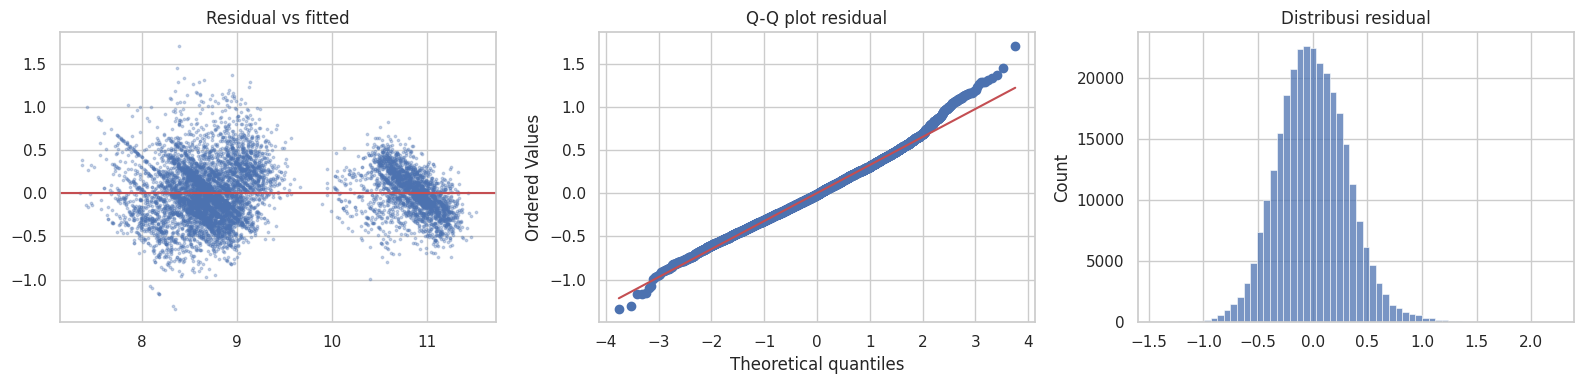

In [13]:
# Diagnostik: VIF, heteroskedastisitas, normalitas residual
X = pd.get_dummies(df[["airline","source_city","destination_city","departure_time","arrival_time","stops","class"]], drop_first=True).astype(float)
X["duration"] = df.duration; X["days_left"] = df.days_left; X = sm_X = X.assign(const=1.0)
samp = X.sample(20000, random_state=0)
vif = pd.Series([variance_inflation_factor(samp.values, i) for i in range(samp.shape[1])], index=samp.columns).drop("const")
print("VIF tertinggi:"); display(vif.sort_values(ascending=False).head(6).round(2))

ols_plain = smf.ols(f, df).fit()
bp = het_breuschpagan(ols_plain.resid, ols_plain.model.exog)
print(f"Breusch-Pagan LM={bp[0]:.0f}, p={bp[1]:.1e}  -> heteroskedastisitas (gunakan robust SE)")

fig, ax = plt.subplots(1,3, figsize=(16,4))
idx = np.random.RandomState(0).choice(len(df), 8000, replace=False)
ax[0].scatter(ols_plain.fittedvalues.iloc[idx], ols_plain.resid.iloc[idx], s=3, alpha=.3); ax[0].axhline(0,c="r"); ax[0].set_title("Residual vs fitted")
stats.probplot(ols_plain.resid.iloc[idx], dist="norm", plot=ax[1]); ax[1].set_title("Q-Q plot residual")
sns.histplot(ols_plain.resid, bins=60, ax=ax[2]); ax[2].set_title("Distribusi residual")
plt.tight_layout(); plt.show()

**Diagnostik:** -- VIF : >5 perlu dicurigai
- **VIF** tertinggi sekitar 5.9 (dummy maskapai), masih di bawah batas umum 10, jadi **multikolinearitas tidak parah**. Meski begitu `duration` dan `stops` berkorelasi (sekitar 0.47), sehingga efek `duration` yang kecil sebagian karena informasinya sudah ditangkap `stops`.
- **Breusch-Pagan** tolak homoskedastisitas, sehingga robust/cluster SE diperlukan.
- Residual **tidak normal dan berpola non-linear** (efek `days_left` yang patah-patah dan interaksi kelas x stop).

menggunakan model OLS baru cukup untuk interpretasi arah dan ukuran efek, namun belum dapat melakukan prediksi terbaik, karena variabel residual masih bersifat tidak konstan, sehingga keputusan" yang didapatkan masih belum valid. Sehingga dilakukan analisis dengan model lain.



## 6. Model prediktif: baseline (pendekatan regresi linear) vs gradient boosting (menggunakan pohon keputusan)

**Penting** : Kode penerbangan yang sama muncul di data latih dan data uji pada split acak. Sehingga perlu dilakukan pembagian data untuk membandingkan :    
- **Random split 80/20** (optimistis),
- **GroupKFold 5-fold menurut kode penerbangan** (dapat memisahkan data berdasarkan identitas grup tertentu. untuk memastikan data dari grup yang sama tidak tersebar. jadi kayak di test nya menggunakan salah satu kelompok, kelompok yang lain sebagai data train).

Metrik pada skala asli (INR): MAE, RMSE, R², dan MAPE. Model dilatih pada `log(price)` kemudian dilakukan *back-transform* dengan `exp`.

In [14]:
df["route"] = df.source_city + "-" + df.destination_city
df["stops_n"] = df.stops.map({"zero":0,"one":1,"two_or_more":2})
df["last15"] = (df.days_left <= 15).astype(int)
cats = ["airline","source_city","destination_city","departure_time","arrival_time","stops","class","route"]
for c in cats: df[c] = df[c].astype("category")
feats = cats + ["duration","days_left","stops_n","last15"]

def metrics(y, p):
    return dict(R2=r2_score(y,p), MAE=mean_absolute_error(y,p), RMSE=mean_squared_error(y,p)**.5, MAPE=(abs(y-p)/y).mean())

params = dict(n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=42)
num_cols = ["duration","days_left","stops_n","last15"]
cat_cols = ["airline","source_city","destination_city","departure_time","arrival_time","stops","class","route"]

def fit_ridge(tr):
    pre = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), cat_cols)], remainder="passthrough")
    return make_pipeline(pre, Ridge(alpha=1.0)).fit(tr[cat_cols+num_cols].astype({c:str for c in cat_cols}), tr.log_price)
def pred_ridge(m, te): return np.exp(m.predict(te[cat_cols+num_cols].astype({c:str for c in cat_cols})))

results = {}
# Random split
tr, te = train_test_split(df, test_size=0.2, random_state=42)
r = fit_ridge(tr); results[("Ridge","Random split")] = metrics(te.price, pred_ridge(r, te))
gbm = lgb.LGBMRegressor(**params).fit(tr[feats], tr.log_price)
p_te = np.exp(gbm.predict(te[feats])); results[("LightGBM","Random split")] = metrics(te.price, p_te)

# GroupKFold by flight code
folds_r, folds_g = [], []
for a, b in GroupKFold(n_splits=5).split(df, groups=df.flight):
    tr_, te_ = df.iloc[a], df.iloc[b]
    folds_r.append(metrics(te_.price, pred_ridge(fit_ridge(tr_), te_)))
    g_ = lgb.LGBMRegressor(**params).fit(tr_[feats], tr_.log_price)
    folds_g.append(metrics(te_.price, np.exp(g_.predict(te_[feats]))))
results[("Ridge","GroupKFold (flight)")] = pd.DataFrame(folds_r).mean().to_dict()
results[("LightGBM","GroupKFold (flight)")] = pd.DataFrame(folds_g).mean().to_dict()

cmp = pd.DataFrame(results).T; cmp.index.names = ["Model","Validasi"]
display(cmp.round(3))

,,R2,MAE,RMSE,MAPE
Model,Validasi,,,,
Ridge,Random split,0.849,4866.980,8812.968,0.244
LightGBM,Random split,0.977,1795.507,3443.577,0.106
Ridge,GroupKFold (flight),0.846,4921.878,8885.052,0.248
LightGBM,GroupKFold (flight),0.950,2754.367,5047.224,0.153


**Interpretasi:**
- LightGBM mengungguli baseline linear secara jelas.
- Performa pada GroupKFold **lebih rendah** daripada random split.

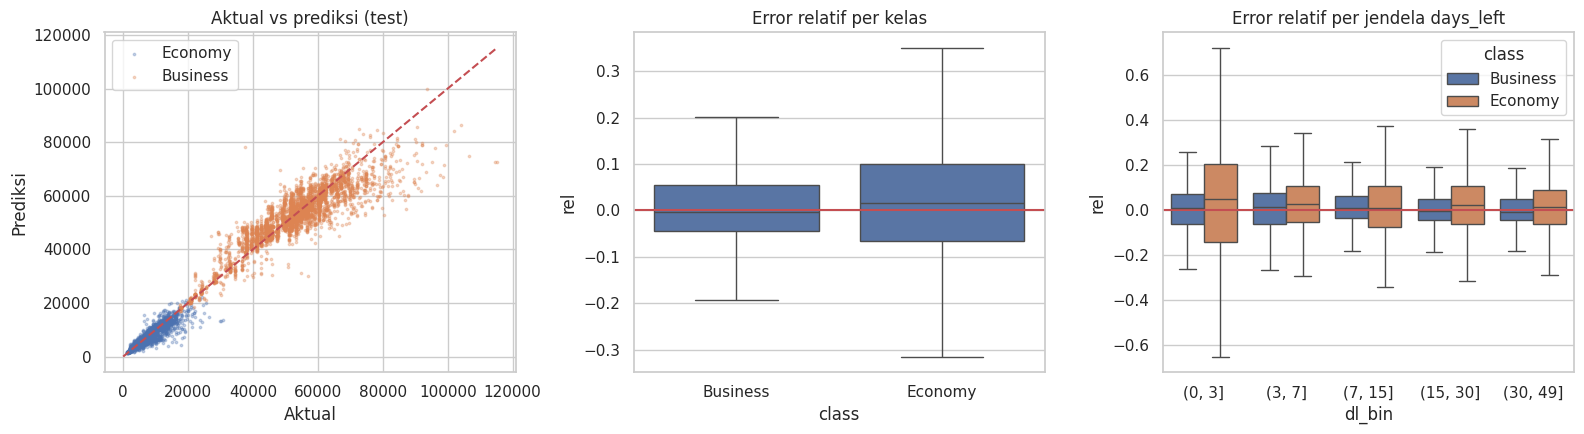

             R2       MAE      RMSE   MAPE
class                                     
Business  0.805  3867.450  5718.687  0.073
Economy   0.825   856.974  1554.331  0.121

Rata-rata error relatif (bias): 0.012
MAPE per kelas x jendela days_left:


/tmp/ipykernel_576/2918959635.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(te.groupby("class", observed=True).apply(lambda g: pd.Series(metrics(g.price, g.pred))).round(3))


dl_bin,"(0, 3]","(3, 7]","(7, 15]","(15, 30]","(30, 49]"
class,,,,,
Business,0.091,0.095,0.075,0.07,0.069
Economy,0.212,0.122,0.126,0.12,0.113


In [16]:
te = te.assign(pred=p_te, err=p_te-te.price, rel=(p_te-te.price)/te.price)
fig, ax = plt.subplots(1,3, figsize=(16,4.5))
for c, col in zip(["Economy","Business"], ["C0","C1"]):
    g = te[te["class"]==c].sample(4000, random_state=0)
    ax[0].scatter(g.price, g.pred, s=3, alpha=.3, c=col, label=c)
lim = [0, te.price.max()]; ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Aktual"); ax[0].set_ylabel("Prediksi"); ax[0].legend(); ax[0].set_title("Aktual vs prediksi (test)")
sns.boxplot(data=te, x="class", y="rel", ax=ax[1], showfliers=False); ax[1].axhline(0,c="r"); ax[1].set_title("Error relatif per kelas")
te["dl_bin"] = pd.cut(te.days_left, [0,3,7,15,30,49])
sns.boxplot(data=te, x="dl_bin", y="rel", hue="class", ax=ax[2], showfliers=False); ax[2].axhline(0,c="r"); ax[2].set_title("Error relatif per jendela days_left")
plt.tight_layout(); plt.show()
print(te.groupby("class", observed=True).apply(lambda g: pd.Series(metrics(g.price, g.pred))).round(3))
print("\nRata-rata error relatif (bias): %.3f" % te.rel.mean())
print("MAPE per kelas x jendela days_left:")
display(te.groupby(["class","dl_bin"], observed=True).rel.apply(lambda x: x.abs().mean()).unstack().round(3))

- model lightGBM mampu menginterpretasikan data kelas ekonomi 82.5% dan 80.5%
- berdasarkan grafik menunjukkan data yang error berdasarkan sisa hari menuju keberangkatan, relatif pada kelompok 1-3 hari menuju keberangkatan untuk kelas ekonomi
- grafik berdasarkan kelas, menunjukkan error (MAPE) pada kelas ekonomi 12.1%, lebih besar dibandingkan kelas bisnis dengan error 7.3%


## 7. Interpretasi model : mencari faktor (fitur) yang berpengaruh terhadap harga

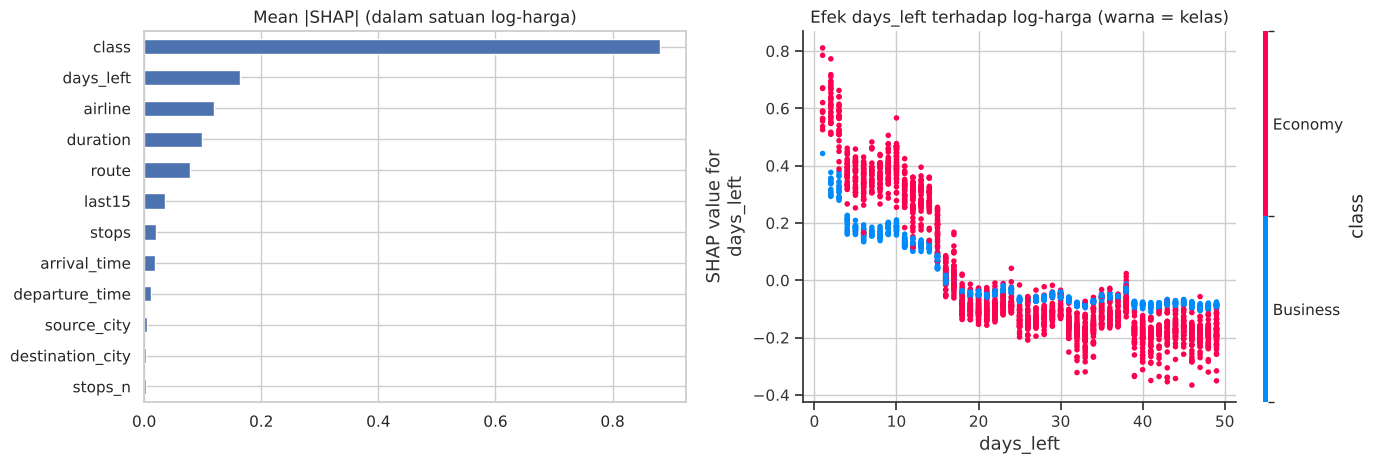

In [ ]:
sample = tr.sample(3000, random_state=0)
explainer = shap.TreeExplainer(gbm) # shap menghitung kontribusi tiap fitur terhadap tiap prediksi, nilai shapley (teori permainan)
sv = explainer.shap_values(sample[feats])
imp = pd.Series(np.abs(sv).mean(0), index=feats).sort_values()
fig, ax = plt.subplots(1,2, figsize=(14,4.8))
imp.plot.barh(ax=ax[0]); ax[0].set_title("Mean |SHAP| (dalam satuan log-harga)")
shap.dependence_plot("days_left", sv, sample[feats], interaction_index="class", ax=ax[1], show=False)
ax[1].set_title("Efek days_left terhadap log-harga (warna = kelas)")
plt.tight_layout(); plt.show()

- Urutan kepentingan (mean |SHAP|): **kelas (sekitar 0.88) jauh di atas** `days_left` (sekitar 0.16), maskapai (0.12), durasi (0.10), dan rute (0.08). `stops` terlihat kecil karena informasinya sudah dibawa oleh `duration` (dan `route`), namun tetap perlu diperhatikan karena berdasarkan OLS dan eta² `stops` terbukti penting
- Dependence plot `days_left` memperlihatkan **pola patah (step)** pada kisaran hari ke-15, bukan garis lurus. Hal ini yang tidak tertangkap OLS linear.

## 8. "Beli sekarang vs tunggu"

**Catatan**: Data kita *cross-section* (tidak ada pelacakan satu tiket yang sama dari waktu ke waktu). Maka "efek menunggu" dihitung secara **counterfactual dari model**: *dengan semua atribut itinerary tetap, berapa harga yang diprediksi jika `days_left` berubah?*. Jadi yang dirubah hari menuju keberangkatannya dan mencari 'kurang berapa hari' yang memiliki perbedaan harga yang besar (lonjakan harian terbesar).

**Langkah:**
1. Efek penyesuaian per jendela `days_left` dengan OLS per kelas (referensi: 30+ hari) beserta CI 95% cluster-robust.
2. Kurva rata-rata harga prediksi per `days_left` (marginal, dari model GBM).
3. Aturan keputusan sederhana *buy / wait*.

/tmp/ipykernel_576/3206953813.py:6: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols('log_price ~ C(win, Treatment("31-49")) + C(airline)+C(route)+C(stops)+C(departure_time)+C(arrival_time)+duration', d).fit(


,kelas,jendela_days_left,premi_pct,lo,hi
0,Economy,1,193.4,182.1,205.1
1,Economy,2-3,167.3,160.1,174.8
2,Economy,4-7,111.0,107.2,114.8
3,Economy,8-15,98.6,95.2,102.0
4,Economy,16-21,13.2,11.8,14.7
5,Economy,22-30,7.3,6.3,8.4
6,Business,1,27.4,22.7,32.2
7,Business,2-3,18.9,17.0,20.8
8,Business,4-7,5.8,4.8,6.8
9,Business,8-15,1.7,1.2,2.2


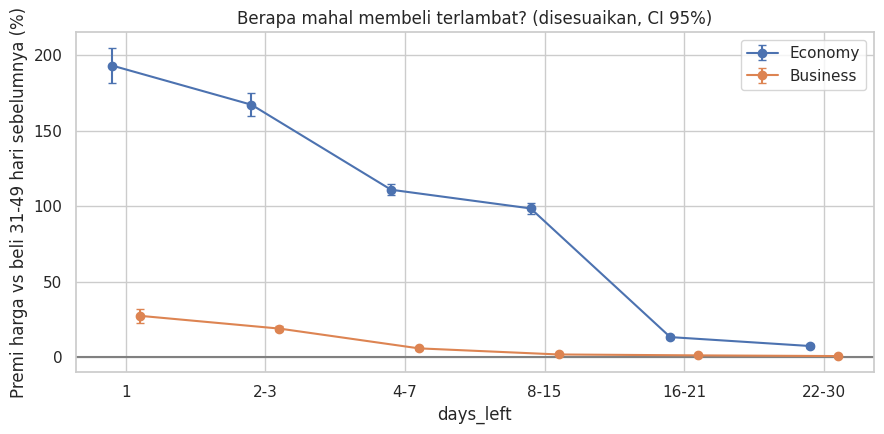

In [17]:
bins = [0,1,3,7,15,21,30,49]; labels = ["1","2-3","4-7","8-15","16-21","22-30","31-49"]
rows = []
for c in ["Economy","Business"]:
    d = df[df["class"]==c].copy()
    d["win"] = pd.cut(d.days_left, bins, labels=labels)
    m = smf.ols('log_price ~ C(win, Treatment("31-49")) + C(airline)+C(route)+C(stops)+C(departure_time)+C(arrival_time)+duration', d).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d.flight)[0]})
    ci = m.conf_int()
    for l in labels[:-1]:
        k = f'C(win, Treatment("31-49"))[T.{l}]'
        rows.append(dict(kelas=c, jendela_days_left=l, premi_pct=(np.exp(m.params[k])-1)*100,
                         lo=(np.exp(ci.loc[k,0])-1)*100, hi=(np.exp(ci.loc[k,1])-1)*100))
adj = pd.DataFrame(rows)
display(adj.round(1))
fig, ax = plt.subplots(figsize=(9,4.5))
for c, off in zip(["Economy","Business"], [-.1,.1]):
    s = adj[adj.kelas==c]; x = np.arange(len(s))+off
    ax.errorbar(x, s.premi_pct, yerr=[s.premi_pct-s.lo, s.hi-s.premi_pct], fmt="o-", capsize=3, label=c)
ax.set_xticks(range(len(labels)-1)); ax.set_xticklabels(labels[:-1]); ax.axhline(0, c="gray")
ax.set_ylabel("Premi harga vs beli 31-49 hari sebelumnya (%)"); ax.set_xlabel("days_left"); ax.legend(); ax.set_title("Berapa mahal membeli terlambat? (disesuaikan, CI 95%)")
plt.tight_layout(); plt.show()

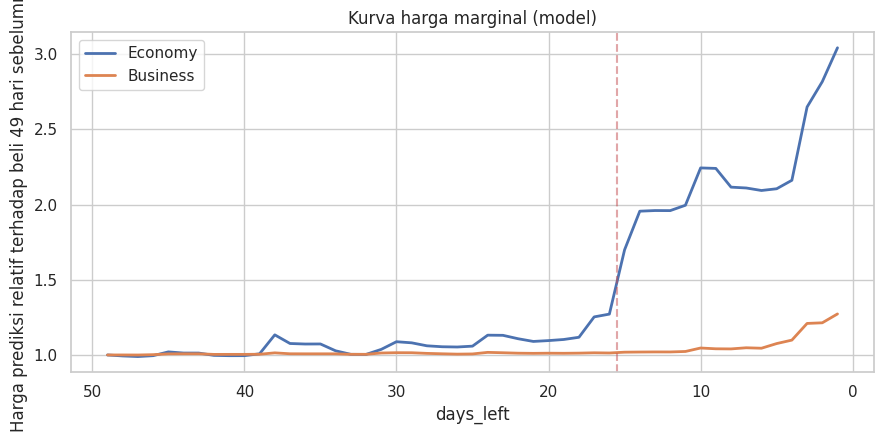

Lonjakan harian terbesar (kenaikan harga saat hari berkurang), Economy:
15    33.6
3     22.5
14    15.1


In [18]:
# Kurva prediksi marginal + titik "tebing harga"
curves = {}
for c in ["Economy","Business"]:
    b = df[df["class"]==c].sample(20000, random_state=1); v = []
    for d in range(1,50):
        x = b.copy(); x["days_left"] = d; x["last15"] = int(d<=15)
        v.append(np.exp(gbm.predict(x[feats])).mean())
    curves[c] = pd.Series(v, index=range(1,50))
cv = pd.DataFrame(curves)
fig, ax = plt.subplots(figsize=(9,4.5))
for c in cv: ax.plot(cv.index, cv[c]/cv[c].iloc[-1], label=c, lw=2)
ax.axvline(15.5, ls="--", c="r", alpha=.5); ax.invert_xaxis(); ax.legend()
ax.set_ylabel("Harga prediksi relatif terhadap beli 49 hari sebelumnya"); ax.set_xlabel("days_left"); ax.set_title("Kurva harga marginal (model)")
plt.tight_layout(); plt.show()
step = (cv.pct_change()*-100).round(1)
print("Lonjakan harian terbesar (kenaikan harga saat hari berkurang), Economy:")
print(cv["Economy"].pct_change(-1).sort_values(ascending=False).head(3).mul(100).round(1).to_string())

In [19]:
def advice(row, wait_days=7, thr=0.03):
    """Rekomendasi sederhana: bandingkan harga prediksi hari ini vs setelah menunggu `wait_days` hari."""
    now = row.copy(); later = row.copy()
    later["days_left"] = max(1, int(row.days_left) - wait_days); later["last15"] = int(later["days_left"] <= 15)
    X = pd.DataFrame([now, later])[feats]
    for c in cats: X[c] = pd.Categorical(X[c], categories=df[c].cat.categories)
    p_now, p_later = np.exp(gbm.predict(X))
    chg = p_later/p_now - 1
    if chg > thr:  act = "BELI SEKARANG (harga diperkirakan naik %.0f%%)" % (chg*100)
    elif chg < -thr: act = "TUNGGU (harga diperkirakan turun %.0f%%)" % (-chg*100)
    else: act = "NETRAL (perubahan harga kecil)"
    return act, round(p_now), round(p_later)

demo = te[(te["class"]=="Economy")].sample(5, random_state=3)
for _, r in demo.iterrows():
    print(f"{r.airline:9s} {r.route:18s} days_left={int(r.days_left):2d} ->", advice(r))

Vistara   Kolkata-Chennai    days_left=30 -> ('BELI SEKARANG (harga diperkirakan naik 15%)', 7977, 9198)
Indigo    Kolkata-Hyderabad  days_left=32 -> ('BELI SEKARANG (harga diperkirakan naik 51%)', 3931, 5917)
Indigo    Delhi-Mumbai       days_left=28 -> ('NETRAL (perubahan harga kecil)', 2767, 2840)
Air_India Hyderabad-Mumbai   days_left=39 -> ('NETRAL (perubahan harga kecil)', 4770, 4753)
Air_India Mumbai-Kolkata     days_left=26 -> ('BELI SEKARANG (harga diperkirakan naik 8%)', 4626, 4992)


### Backtest aturan beli/tunggu (agregat, data uji saja)

Karena tidak ada data pelacakan satu tiket, validasi dilakukan di **level sel** (maskapai x rute x kelas x stop) - data kunci yang  menjadi acuan untuk kode penerbangan : untuk setiap sel dan pasangan hari (d+7, d), bandingkan arah keputusan model dengan **perubahan harga rata-rata sebenarnya pada baris data uji** (data yang tidak dipakai saat training).

In [ ]:
cell = ["airline","route","class","stops"]
agg = te.groupby(cell+["days_left"], observed=True).price.agg(["mean","size"]).reset_index()
later = agg.rename(columns={"mean":"p_later","size":"n_later"})
now_  = agg.assign(days_left=agg.days_left-7).rename(columns={"mean":"p_now","size":"n_now"})
bt = now_.merge(later, on=cell+["days_left"]); bt = bt[(bt.n_now>=3)&(bt.n_later>=3)].copy()
bt["d_now"] = bt.days_left + 7
tmpl = df.groupby(cell, observed=True).agg(source_city=("source_city", lambda x: x.mode().iat[0]), destination_city=("destination_city", lambda x: x.mode().iat[0]),
        departure_time=("departure_time", lambda x: x.mode().iat[0]), arrival_time=("arrival_time", lambda x: x.mode().iat[0]),
        duration=("duration","median"), stops_n=("stops_n","first")).reset_index()
bt = bt.merge(tmpl, on=cell)
def P(dvals):
    z = bt.copy(); z["days_left"] = dvals; z["last15"] = (dvals<=15).astype(int)
    for c in cats: z[c] = pd.Categorical(z[c], categories=df[c].cat.categories)
    return np.exp(gbm.predict(z[feats]))
bt["pred_chg"] = P(bt.days_left)/P(bt.d_now) - 1
bt["act_chg"] = bt.p_later/bt.p_now - 1
bt["call"] = np.where(bt.pred_chg>.03, "BELI SEKARANG", np.where(bt.pred_chg<-.03, "TUNGGU", "NETRAL"))
out = bt.groupby("call").agg(n=("act_chg","size"), rata2_perubahan_aktual=("act_chg","mean"), median_aktual=("act_chg","median"), pct_harga_naik=("act_chg", lambda s: (s>0).mean()))
display(out.round(3))
print("Korelasi perubahan prediksi vs aktual:", round(np.corrcoef(bt.pred_chg, bt.act_chg)[0,1],3), "| jumlah pasangan:", len(bt))

,n,rata2_perubahan_aktual,median_aktual,pct_harga_naik
call,,,,
BELI SEKARANG,2410,0.318,0.159,0.786
NETRAL,2999,0.013,0.001,0.506
TUNGGU,206,-0.099,-0.103,0.248


Korelasi perubahan prediksi vs aktual: 0.841 | jumlah pasangan: 5615


**Temuan utama untuk bisnis:**
- Di **Economy**, ada **"tebing harga" di sekitar hari ke-15**: dibandingkan membeli 31-49 hari sebelumnya, premi harga hanya sekitar +7% (22-30 hari) dan +13% (16-21 hari), lalu **melonjak ke sekitar +99% (8-15 hari)**, +111% (4-7 hari), dan +167% sampai +193% (3 hari terakhir). Lonjakan harian terbesar terjadi saat melewati hari ke-15 (sekitar +34%).
- Di **Business**, harga jauh lebih stabil: premi di bawah 2% sampai 8-15 hari, sekitar +6% pada 4-7 hari, dan baru terasa pada 3 hari terakhir (sekitar +19% sampai +27%).
- Aturan praktis: membeli **sebelum ambang 15 hari** (idealnya 16-21 hari ke atas) menghindari lonjakan terbesar. Menunggu dari 30 hari ke 16 hari "hanya" menambah sekitar 6 poin persentase, tetapi **melewati hari ke-15 hampir menggandakan harga Economy**.
- **Backtest agregat pada data uji:** sel dengan keputusan "BELI SEKARANG" memang mengalami kenaikan harga rata-rata sekitar +32% (79% sel naik), sedangkan "TUNGGU" rata-rata turun sekitar -10%; korelasi perubahan prediksi vs aktual sekitar 0.84. Sinyal "TUNGGU" jarang muncul (sekitar 4% kasus), karena harga hampir selalu naik mendekati hari H.
- Rekomendasi per-itinerary dari model (contoh di atas) bersifat **berisik** karena pola tiap rute/maskapai bisa berbeda; jangan ditampilkan ke pengguna tanpa validasi seperti backtest di bawah.

## 9. Kesimpulan dan keterbatasan

**Kesimpulan**
1. Harga ditentukan terutama oleh **kelas**, **jumlah stop**, **maskapai**, dan **waktu pembelian (days_left)**. Kota dan jam berangkat berpengaruh kecil.
2. Memodelkan **log(harga)** menstabilkan varians dan memberi interpretasi persentase.
3. **Simpson's paradox** muncul pada `stops` dan `airline`: selalu kontrol atau stratifikasi menurut `class`.
4. **LightGBM** mengungguli OLS/Ridge, dan evaluasi jujur harus memakai **GroupKFold menurut kode penerbangan**.
5. Ada **ambang harga sekitar 15 hari** sebelum keberangkatan, dasar yang kuat untuk fitur "beli sekarang vs tunggu".

